In [1]:
import os
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
import glob
import ipywidgets as widgets

from IPython.display import display, clear_output

c:\Users\juan_\AppData\Local\Programs\Python\Python310\lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.25.905) or chardet (7.6.0)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


In [2]:
# Route example for a downloaded subject
subject_path = r"C:\Users\juan_\Desktop\cv-medical\COBRE_Dataset\sub-10159\anat\sub-10159_T1w.nii.gz"

# 1. Load the NIfTI file with nibabel
nii_img = nib.load(subject_path)
mri_data = nii_img.get_fdata()

print(f"Volume Dimensions of the Brain: {mri_data.shape}")
# Generally, this will give you something like (256, 256, 176)

# 2. Extract a central slice of the brain in the axial axis
slice_idx = mri_data.shape[2] // 2
axial_slice = mri_data[:, :, slice_idx]

Volume Dimensions of the Brain: (176, 256, 256)


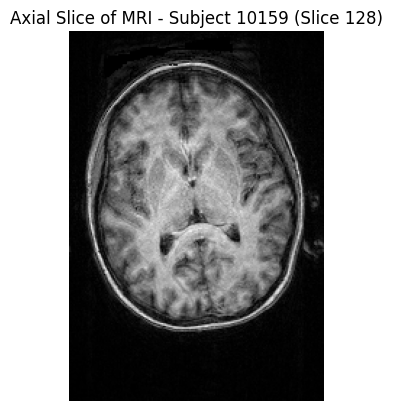

In [3]:
# 3. Quick visualization to verify that the data loaded correctly
plt.imshow(axial_slice.T, cmap="gray", origin="lower")
plt.title(f"Axial Slice of MRI - Subject 10159 (Slice {slice_idx})")
plt.axis("off")
plt.show()

## Interactive Function

In [4]:
# 1. Dynamically scan directory for valid subjects (no hardcoding)
data_dir = r"C:\Users\juan_\Desktop\cv-medical\COBRE_Dataset"
subject_paths = sorted(glob.glob(os.path.join(data_dir, "sub-*", "anat", "*_T1w.nii.gz")))
subject_ids = [os.path.basename(p).split('_')[0] for p in subject_paths]

print(f"Total subjects dynamically found: {len(subject_ids)}")

if len(subject_ids) == 0:
    raise ValueError("No subjects found. Please check your dataset path.")

# 2. Define robust viewing function for interactive slider
def view_brain_scan(subject_index):
    # Clear previous plot output cleanly
    clear_output(wait=True)
    
    # Get current subject path and ID
    img_path = subject_paths[subject_index]
    subject_id = subject_ids[subject_index]
    
    # Load 3D NIfTI volume using nibabel
    nii_img = nib.load(img_path)
    volume = nii_img.get_fdata()
    
    # Extract central axial slice
    slice_idx = volume.shape[2] // 2
    axial_slice = volume[:, :, slice_idx]
    
    # Plot the slice
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(axial_slice.T, cmap="gray", origin="lower")
    ax.set_title(f"Subject: {subject_id} | Index: {subject_index + 1}/{len(subject_ids)} | Slice: {slice_idx}")
    ax.axis("off")
    plt.show()

# 3. Launch interactive slider widget (native & stable in VS Code)
widgets.interact(
    view_brain_scan, 
    subject_index=widgets.IntSlider(
        min=0, 
        max=len(subject_ids) - 1, 
        step=1, 
        value=0, 
        description='Subject:'
    )
)

Total subjects dynamically found: 265


interactive(children=(IntSlider(value=0, description='Subject:', max=264), Output()), _dom_classes=('widget-in…

<function __main__.view_brain_scan(subject_index)>